# Tomato Disease Image Classification

Project **Tomato Disease Image Classification** ini bertujuan untuk membangun sistem kecerdasan buatan yang mampu mengidentifikasi berbagai penyakit pada daun tomat secara otomatis berdasarkan citra digital. Dataset yang digunakan terdiri dari beberapa kelas penyakit seperti *Late Blight*, *Septoria Leaf Spot*, serta *Healthy*, yang diambil dari sumber publik *Kaggle* dengan resolusi gambar yang bervariasi. Proyek ini menerapkan tahapan standar industri mulai dari data *preprocessing* (*resizing*, *normalization*, dan *augmentation*), data *splitting* (*train*, *val*, dan *test set*), hingga pembangunan model menggunakan arsitektur *Convolutional Neural Network* (*CNN*). Model kemudian dievaluasi menggunakan metrik *accuracy*, *precision*, *recall*, dan *F1-score* untuk memastikan performa yang optimal.


Mari kita mulai dari install library tensorflowjs. Library ini nantinya akan kita gunakan untuk menyimpan model yang telah berhasil dilatih pada tahap *model building*.

In [1]:
# Install library yang diperlukan
!pip install tensorflowjs

## Kaggle Setup

Tahapan awal dari project ini adalah setup untuk penggunaan kaggle. Pertama kita akan melakukan upload kaggle.json dengan kode di bawah ini. Mengupload file ini bertujuan agar kita dapat memanggil API kaggle untuk mendownload dataset yang ada di kaggle.

In [ ]:
# Upload file API dari kaggle
from google.colab import files
files.upload()

## Download Kaggle Dataset

In [3]:
# Buat folder untuk menyimpan data yang didownload dari kaggle
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Download kaggle tomato diseases dataset and unzip the file
!kaggle datasets download -d cookiefinder/tomato-disease-multiple-sources
!unzip tomato-disease-multiple-sources.zip

Streaming output truncated to the last 5000 lines.
  inflating: valid/Late_blight/9afc2537-1b13-4c25-b5ed-5b8de511b0ab___GHLB2 Leaf 9033.JPG  
  inflating: valid/Late_blight/9bb49d22-976d-40c3-bc9a-bff5cbbd8e28___RS_Late.B 5057.JPG  
  inflating: valid/Late_blight/9c274db5-2f89-4f3c-b9e2-4d5ebc54ddad___GHLB2 Leaf 9096.JPG  
  inflating: valid/Late_blight/9c726f4e-045b-4080-b53d-d7e66d45bcb1___RS_Late.B 4876.JPG  
  inflating: valid/Late_blight/9e5dd34f-124c-4a64-ba9f-77c8d05faa9c___GHLB2 Leaf 8749.JPG  
  inflating: valid/Late_blight/9e633823-3dde-450c-8172-733021e4dff0___RS_Late.B 6414.JPG  
  inflating: valid/Late_blight/9ecb8001-2f48-4487-b287-535dbcfb5c2f___RS_Late.B 6206.JPG  
  inflating: valid/Late_blight/9f7dcd60-e691-4c1e-830e-7495f7cc123d___RS_Late.B 6166.JPG  
  inflating: valid/Late_blight/Bacterial_spots2276_jpg.rf.5becd3793ec2a532bf8f111d60911c63.jpg  
  inflating: valid/Late_blight/IMG_1526_jpg.rf.5e25005985e2b12a6f52bfa7120f3eee.jpg  
  inflating: valid/Late_blight/IMG_

## Import Libraries

In [4]:
# Standard Libraries
import os                     # Operasi sistem file
import shutil                 # Menyalin, memindahkan, dan menghapus file/folder
import random                 # Operasi random sederhana
import numpy as np            # Komputasi numerik dan array multidimensi
import matplotlib.pyplot as plt  # Visualisasi grafik
import seaborn as sns         # Visualisasi statistik berbasis matplotlib
from pathlib import Path      # Manipulasi path file secara modern
from PIL import Image         # Membaca dan memproses gambar

# TensorFlow
import keras                  # High-level API untuk deep learning
import tensorflow as tf       # Framework utama deep learning
# import tensorflowjs as tfjs   # TensorFlow.js untuk konversi model ke format JavaScript
from tensorflow.keras.optimizers import Adam  # Optimizer Adam untuk training model
from tensorflow.keras.layers import (
    Input,            # Layer input model
    Conv2D,           # Layer convolution untuk ekstraksi fitur gambar
    MaxPooling2D,     # Downsampling feature map
    Dense,            # Fully connected layer
    Flatten,          # Mengubah feature map menjadi vector
    RandomFlip,       # Augmentasi flip gambar
    RandomRotation,   # Augmentasi rotasi gambar
)
from tensorflow.keras.models import Sequential  # Model neural network berurutan
from tensorflow.keras.callbacks import (
    Callback,            # Membuat custom callback
    EarlyStopping,       # Menghentikan training jika tidak ada peningkatan
    ReduceLROnPlateau    # Mengurangi learning rate saat validation stagnan
)

# Scikit-learn
from sklearn.model_selection import train_test_split  # Membagi dataset train/val/test
from sklearn.utils.class_weight import compute_class_weight  # Menghitung bobot kelas untuk dataset imbalance
from sklearn.preprocessing import label_binarize  # Mengubah label menjadi format biner (one-vs-rest)
from sklearn.metrics import (
    accuracy_score,        # Menghitung akurasi model
    confusion_matrix,      # Membuat confusion matrix
    classification_report, # Precision, Recall, F1-score per kelas
    roc_curve,             # Menghitung nilai ROC curve
    auc                    # Menghitung Area Under Curve (AUC)
)

## Dataset Preprocessing

### Merge Dataset

Setelah berhasil melakukan download dataset dari kaggle dan import library yang akan digunakan, selanjutnya adalah mempersiapkan datanya sebelum masuk ke tahap preprocessing. Karena dataset bawaan dari kaggle masih terpisah menjadi 'train' dan 'valid', kita akan menyatukannya terlebih dahulu dengan fungi *merge_dir* di bawah ini.

#### Config

In [5]:
# Config
TRAIN_DIR = '/content/train' # Path data train
VALIDATIO_DIR = '/content/valid' # Path data validation
SRC_DIR = [TRAIN_DIR, VALIDATIO_DIR]
DST_DIR = '/content/tomato-disease-dataset' # Path data hasil gabungan

#### Utility

In [6]:
def merge_dir(src_dirs, dst_dir):
  """
  Menggabungkan beberapa direktori dataset menjadi satu direktori gabungan.

  Args:
    - src_dirs (list): Direktori sumber yang ingin digabung.
    - dst_dir (str): Direktori destinasi hasil penggabungan.
  """

  # Membuat direktori destinasi jika belum ada
  dst_path = Path(dst_dir)
  dst_path.mkdir(parents=True, exist_ok=True)

  # Iterasi setiap direktori sumber
  for src_dir in src_dirs:
    # Lewati jika direktori tidak ditemukan
    if not os.path.exists(src_dir):
      raise FileNotFoundError(f"Direktori {src_dir} tidak ditemukan.")

    # Iterasi setiap kelas di direktori sumber
    for class_name in os.listdir(src_dir):
      class_name_path = os.path.join(src_dir, class_name)

      # Proses hanya folder kelas
      if os.path.isdir(class_name_path):
        dst_class_name_path = os.path.join(dst_path, class_name.lower())
        os.makedirs(dst_class_name_path, exist_ok=True)

        # Iterasi file dalam kelas
        for file in os.listdir(class_name_path):
          src_file = os.path.join(class_name_path, file)
          dst_file = os.path.join(dst_class_name_path, file)

          # Salin file ke direktori destinasi
          if os.path.isfile(src_file):
            try:
              shutil.copy2(src_file, dst_file)
            except Exception as e:
              print(f"Gagal salin {src_file}: {e}")

        print(f"Berhasil merge: {class_name_path} ke {dst_class_name_path}")

    print("Merge direktori berhasil.\n")

#### Execution

Setelah fungsi untuk menggabungkan direktori berhasil dibuat, selanjutnya mari kita jalankan fungsi tersebut dengan kode di bawah.

In [7]:
# Eksekusi fungsi merge_dir
merge_dir(SRC_DIR, DST_DIR)

Berhasil merge: /content/train/Early_blight ke /content/tomato-disease-dataset/early_blight
Berhasil merge: /content/train/healthy ke /content/tomato-disease-dataset/healthy
Berhasil merge: /content/train/Leaf_Mold ke /content/tomato-disease-dataset/leaf_mold
Berhasil merge: /content/train/powdery_mildew ke /content/tomato-disease-dataset/powdery_mildew
Berhasil merge: /content/train/Tomato_mosaic_virus ke /content/tomato-disease-dataset/tomato_mosaic_virus
Berhasil merge: /content/train/Bacterial_spot ke /content/tomato-disease-dataset/bacterial_spot
Berhasil merge: /content/train/Spider_mites Two-spotted_spider_mite ke /content/tomato-disease-dataset/spider_mites two-spotted_spider_mite
Berhasil merge: /content/train/Target_Spot ke /content/tomato-disease-dataset/target_spot
Berhasil merge: /content/train/Septoria_leaf_spot ke /content/tomato-disease-dataset/septoria_leaf_spot
Berhasil merge: /content/train/Tomato_Yellow_Leaf_Curl_Virus ke /content/tomato-disease-dataset/tomato_yello

### Filter Selected Category

Dataset yang di-*download* dari *Kaggle* berisikan 11 kelas. Namun, pada *project* ini hanya menggunakan 3 kelas saja yaitu, *Late Blight*, *Septoria Leaf Spot*, dan *Healthy*. Maka dari itu, kita akan melakukan *filter dataset* terlebih dahulu sebelum melakukan *train test split*.

#### Config

In [8]:
# Config
SRC_DIR = "/content/tomato-disease-dataset" # Path dataset sumber
DST_DIR = "/content/filtered-dataset" # Path dataset hasil filter
# Kelas yang ingin difilter
SELECTED_CLASSES = [
    "septoria_leaf_spot",
    "late_blight",
    "healthy"
]

#### Utility

In [9]:
def filter_dataset(src_dir, dst_dir, selected_classes):
  """
  Filter dataset berdasarkan kelas yang diinginkan

  Args:
    - src_dir: Direktori sumber dataset
    - dst_dir: Direktori destinasi dataset yang sudah difilter
    - selected_classes: Kelas yang ingin difilter
  """

  src_path = Path(src_dir) # Path dataset sumber
  dst_path = Path(dst_dir) # Path dataset destinasi
  # Membuat direktori destinasi
  dst_path.mkdir(parents=True, exist_ok=True)

  # Ambil daftar kelas yang tersedia
  available_classes = [path.name for path in src_path.iterdir() if path.is_dir()]

  # Validasi kelas yang ingin difilter
  for class_name in selected_classes:
    if class_name not in available_classes:
      raise ValueError(f"Kelas {class_name} tidak ada di dataset")

  # Salin hanya kelas yang dipilih
  for class_name in selected_classes:
    src_class_name_path = src_path / class_name
    dst_class_name_path = dst_path / class_name

    # Hapus folder tujuan jika sudah ada
    if dst_class_name_path.exists():
      shutil.rmtree(dst_class_name_path)

    # Salin seluruh isi kelas
    shutil.copytree(src_class_name_path, dst_class_name_path)

  print("Filtering selesai.")
  print(f"Total kelas yang difilter: {len(selected_classes)}, {selected_classes}")

#### Execution

In [10]:
# Eksekusi fungsi filter_dataset
filter_dataset(SRC_DIR, DST_DIR, SELECTED_CLASSES)

Filtering selesai.
Total kelas yang difilter: 3, ['septoria_leaf_spot', 'late_blight', 'healthy']


Berdasarkan hasil dari kode di atas, kita telah berhasil melakukan *filter* terhadap kelas yang diinginkan, yaitu *Late Blight*, *Septoria Leaf Spot*, dan *Healthy*.

### Split Dataset into Train, Val, and Test

Setelah berhasil melakukan *filtering* terhadap kelas yang diinginkan, selanjutnya adalah memisahkan *dataset* yang telah dipersiapkan menjadi 3 bagian, yaitu *training*, *validation*, dan *testing set*. Namun, sebelum memisahkan data, akan ada beberapa fungsi *utility* yang akan dipersiapkan seperti *create_split_dir*, *is_valid_image*, *select_all_images*, *split_dataset*, dan *move_set_data* sebelum melakukan pemisahan *set* data. Berikut penjelasan fungsi *utility* yang akan digunakan.

1. *create_split_dir*: Fungsi ini akan membuat direktori untuk tiap *split* *train*, *val* dan *test*.
2. *is_valid_image*: Fungsi ini dipakai untuk memeriksa apakah *file* gambar memiliki isi yang valid atau tidak.
3. *select_all_images*: Fungsi ini berguna untuk mengambil semua *path* gambar yang ada pada direktori.
4. *split_dataset*: Fungsi ini adalah fungsi utama, yaitu melakukan *split dataset*.
5. *move_set_data*: Fungsi ini digunakan untuk memindahkan dataset yang sudah di-split ke direktori tujuan (direktori khusus data *train*, *val*, dan *test*).

#### Config

In [11]:
# Config
SRC_DIR = '/content/filtered-dataset' # Path sumber dataset yang ingin di-split
DST_DIR = '/content/dataset' # Path destinasi hasil split dataset
TRAIN_RATIO = 0.7   # Ratio training set
VAL_RATIO = 0.15    # Ratio validation set
TEST_RATIO = 0.15   # Ratio testing set
TRAIN_SET_PATH = '/content/dataset/train' # Path dataset train
VAL_SET_PATH = '/content/dataset/val' # Path dataset val
TEST_SET_PATH = '/content/dataset/test' # Path dataset test
SPLITS = ['train', 'val', 'test']
EXTENSIONS = ('.jpg', '.jpeg') # Ekstensi gambar yang valid
SEED = 42           # Seed untuk memastikan hasil random konsisten

# Mengatur seed pada modul random Python agar pembagian data konsisten
random.seed(SEED)

#### Utilities

In [12]:
def create_split_dir(splits, dst_dir):
  """
  Membuat direktori untuk dataset yang akan di-split

  Args:
    - splits: Pembagian split untuk dataset.
    - dst_dir: Direktori destinasi untuk dataset yang di-split
  """
  # Loop setiap split yang ingin dibuatkan direktori
  for split in splits:
    split_path = os.path.join(dst_dir, split)
    os.makedirs(split_path, exist_ok=True)

  print("Direktori split berhasil dibuat.")

In [13]:
def is_valid_image(path, img_ext):
  """
  Memeriksa apakah file gambar memiliki isi yang valid

  Args:
    - path: Path dari gambar yang ingin diperiksa
    - img_ext: Ekstensi gambar yang valid
  """
  try:
    # Memeriksa apakah file kosong
    if os.path.getsize(path) == 0:
      return False

    image = tf.io.read_file(path) # Membaca file gambar
    tf.image.decode_jpeg(image, channels=3) # Memvalidasi apakah gambar dapat didecode atau tidak

    # Return true jika gambar valid
    return True

  except:
    # Return false jika gambar tidak valid atau ada kesalahan dalam membaca file gambar
    return False

def select_all_images(src_dir, img_ext):
  """
  Memilih semua gambar yang ada pada direktori sumber

  Args:
    - src_dir: Direktori sumber tempat gambar yang ingin diambil tersimpan
    - img_ext: Extension dari gambar yang akan diambil

  Returns:
    - image_list: Semua path gambar yang sesuai extension yang berhasil dipilih
  """

  # Menyimpan daftar path gambar yang valid
  image_list = []

  # Loop setiap kelas yang ada di dalam direktori sumber
  for class_name in os.listdir(src_dir):
    class_name_path = os.path.join(src_dir, class_name)

    # Jika path bukanlah sebuah direktori, skip direktori tersebut
    if not os.path.isdir(class_name_path):
      continue

    # Iterasi setiap file gambar dalam kelas
    for img in os.listdir(class_name_path):
      img_path = os.path.join(class_name_path, img)

      # Lewati jika bukan ekstensi gambar yang diizinkan
      if not img.lower().endswith(img_ext):
        continue

      # Cek apakah gambar valid, simpan jika valid
      if is_valid_image(img_path, img_ext):
        image_list.append(img_path)
      else:
        print(f"File invalid: {img_path}")

        try:
          os.remove(img_path) # Hapus file gambar yang rusak
          print(f"Berhasil meghapus {img_path}")
        except Exception as e:
          print(f"Gagal meghapus {img_path}: {e}")

  return image_list

In [14]:
def split_dataset(
    data,
    train_ratio,
    val_ratio,
    test_ratio,
    seed
):
  """
  Melakukan split terhadap keseluruhan dataset menjadi tiga bagian (train, val, test)

  Args:
    - data: Dataset yang ingin di-split
    - train_ratio: Rasio pembagian dataset untuk training
    - val_ratio: Rasio pembagian dataset untuk validation
    - test_ratio: Rasio pembagian dataset untuk testing
    - seed: Seed untuk memastikan hasil random konsisten

  Returns:
    - train_data: Dataset train yang telah di-split
    - val_data: Dataset validation yang telah di-split
    - test_data: Dataset test yang telah di-split
  """
  # Memastikan  total rasio split (train + val + test) = 1.0
  assert abs(train_ratio +  val_ratio + test_ratio - 1.0) < 1e-6

  labels = [Path(class_name).parent.name for class_name in data]

  # Split data menjadi train set dan data temporary set
  train_data, temp_data, train_labels, temp_labels = train_test_split(
      data,
      labels,
      test_size=(1 - train_ratio),
      random_state=seed,
      stratify=labels
  )

  # Ratio untuk test set setelah data di-split menjadi 2 bagian
  relative_test_ratio = test_ratio / (val_ratio + test_ratio)

  # Split data temporary set pada tahap sebelumnya menjadi val dan test set
  val_data, test_data, _, _ = train_test_split(
      temp_data,
      temp_labels,
      test_size=relative_test_ratio,
      random_state=seed,
      stratify=temp_labels
  )

  # Return data train, val, dan test
  return train_data, val_data, test_data

In [15]:
def move_set_data(set_data, dst_dir, img_ext):
  dst_dir = Path(dst_dir) # Path dataset destinasi

  print("Pemindahan data dimulai...")
  # Iterasi setiap path gambar
  for img_path in map(Path, set_data):
    # Validasi file dan ekstensi
    if not img_path.is_file() or img_path.suffix.lower() not in img_ext:
      continue

    # Direktori destinasi berdasarkan kelas
    output_dir = dst_dir / img_path.parent.name

    try:
      output_dir.mkdir(parents=True, exist_ok=True) # Membuat direktori destinasi jika belum ada
      dst_file = output_dir / img_path.name # Path file destinasi

      # Salin file jika belum ada di destinasi
      if not dst_file.exists():
        shutil.copy2(img_path, dst_file)

    # Menangani dan memberi pesan error saat proses pemindahan
    except Exception as e:
      print(f"Gagal memproses {img_path}: {e}")

  print("\nSet data berhasil dipindahkan")

#### Execution

Dengan kode di atas, berarti fungsi *utility* telah berhasil dibuat. Selanjutnya pada kode di bawah, fungsi-fungsi yang telah dipersiapkan tersebut akan dieksekusi untuk membuat *split* direktori, mengecek validitas gambar, lalu memasukkan semua *path* gambar yang valid ke dalam sebuah *list*, kemudian dilakukan *train test split* terhadap *list path* gambar tadi, lalu yang terakhir memindahkan *set* data yang telah di-*split* tadi ke direktori destinasi masing-masing.

In [16]:
# Eksekusi fungsi create_split_dir
create_split_dir(SPLITS, DST_DIR)

Direktori split berhasil dibuat.


In [17]:
# Eksekusi fungsi select_all_images
images = select_all_images(SRC_DIR, EXTENSIONS)

In [18]:
# Eksekusi fungsi split_dataset
train_data, val_data, test_data = split_dataset(images, TRAIN_RATIO, VAL_RATIO, TEST_RATIO, SEED)

In [19]:
# Eksekusi fungsi move_set_data untuk split train
move_set_data(train_data, TRAIN_SET_PATH, EXTENSIONS)

Pemindahan data dimulai...

Set data berhasil dipindahkan


In [20]:
# Eksekusi fungsi move_set_data untuk split val
move_set_data(val_data, VAL_SET_PATH, EXTENSIONS)

Pemindahan data dimulai...

Set data berhasil dipindahkan


In [21]:
# Eksekusi fungsi move_set_data untuk split test
move_set_data(test_data, TEST_SET_PATH, EXTENSIONS)

Pemindahan data dimulai...

Set data berhasil dipindahkan


## Exploratory Data Analysis

Setelah berhasil melakukan langkah sebelumnya yaitu memisahkan *set* data *train*, *val*, dan *test*, langkah selanjutnya adalah melihat distribusi dan visualisasi dari *dataset* yang telah dipersiapkan.

### Category Distribution Plot

Pertama-tama, kita akan membuat fungsi untuk menampilkan distribusi dataset dengan fungsi di bawah.

#### Config

In [22]:
# Config
SRC_DIR = '/content/dataset' # Path dataset sumber
EXTENSIONS = ('.jpg', '.jpeg') # Ekstensi gambar yang valid
THRESHOLD = 1.5 # Batas ambang imbalance dataset

#### Utility

In [23]:
def plot_class_names_distribution(src_dir, split, img_ext, threshold):
  """
  Menampilkan distribusi kelas dalam dataset

  Args:
    - src_dir: Direktori sumber dataset
    - split: Split dataset yang ingin ditampilkan
    - img_ext: Ekstensi gambar yang valid
    - threshold: Batas ambang imbalance
  """


  split_path = os.path.join(src_dir, split)   # Path dataset untuk split tertentu (train/val/test)
  class_names = sorted(os.listdir(split_path)) # Ambil daftar kelas
  counts = [] # Menyimpan jumlah gambar per kelas

  # Iterasi tiap kelas dan filter hanya file dengan ekstensi gambar yang diizinkan
  for class_name in class_names:
    class_name_path = os.path.join(split_path, class_name)
    images = [
        img for img in os.listdir(class_name_path)
        if img.lower().endswith(img_ext)
    ]

    # Simpan jumlah gambar pada kelas
    counts.append(len(images))

  counts = np.array(counts) # Konversi ke array numpy
  total_samples = counts.sum() # Total seluruh gambar
  percentages = (counts / total_samples) * 100 # Persentase distribusi tiap kelas

  # Imbalance Checking
  max_count = counts.max() # Jumlah sampel maksimum
  min_count = counts.min() # Jumlah sampel minimum
  imbalance_ratio = max_count / min_count if min_count > 0 else np.inf # Rasio ketidakseimbangan

  print(f"Ringkasan Distribusi Data ({split.upper()} SET)")
  print(f"Total Data : {total_samples}")
  print(f"Maks Sampel: {max_count}")
  print(f"Min Sampel : {min_count}")
  print("Ratio Imbalance: {:.2f}\n".format(imbalance_ratio))

  # Visualization
  plt.figure(figsize=(12, 7)) # Membuat figure visualisasi
  bars = plt.barh(class_names, counts) # Bar chart horizontal distribusi kelas

  plt.title(f"Distribusi Kelas Set {split.capitalize()}", fontsize=14)
  plt.xlabel("Jumlah Gambar")
  plt.ylabel("Kelas")

  # Menambahkan label jumlah dan persentase pada setiap bar
  for i, bar in enumerate(bars):
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f"{counts[i]} ({percentages[i]:.1f}%)",
        va='center'
    )

  plt.tight_layout()
  plt.show()

#### Execution

Setelah berhasil mendefinisikan fungsi plot_class_names_distribution, eksekusi fungsi tersebut dengan menjalankan kode di bawah sesuai dengan split tertentu.

Ringkasan Distribusi Data (TRAIN SET)
Total Data : 7620
Maks Sampel: 2575
Min Sampel : 2506
Ratio Imbalance: 1.03



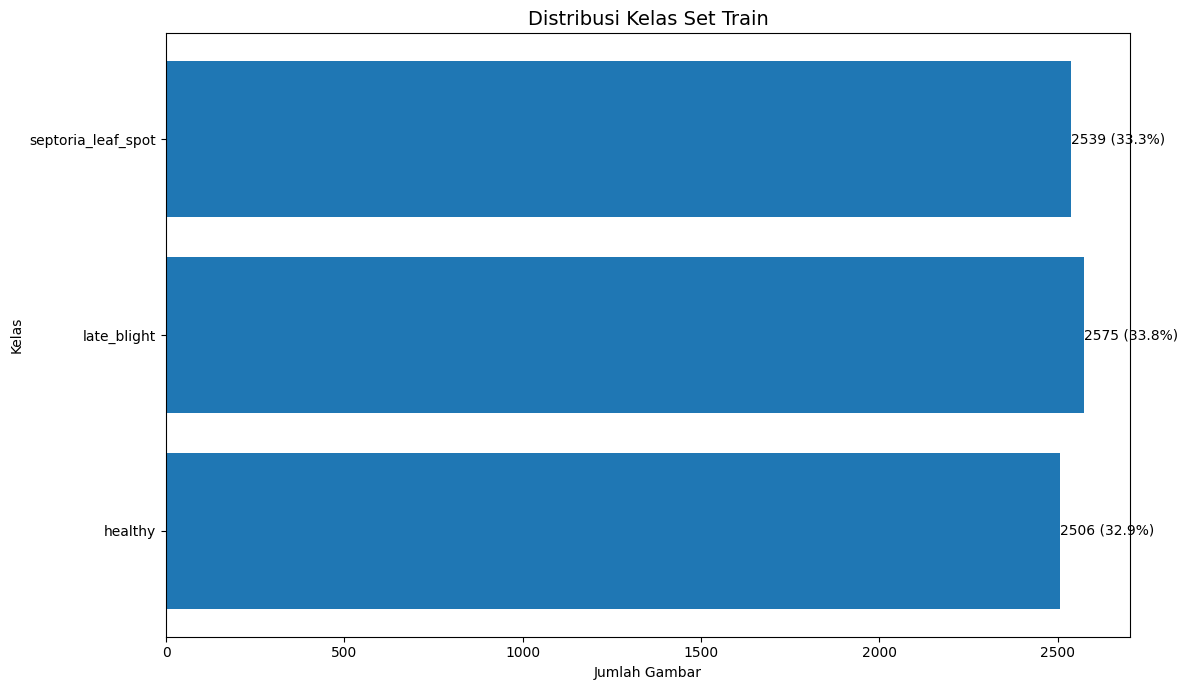

In [24]:
# Eksekusi fungsi plot_class_names_distribution untuk split train
plot_class_names_distribution(SRC_DIR, "train", EXTENSIONS, THRESHOLD)

Berdasarkan distribusi plot dari split train di atas, dapat dilihat bahwa;
1. Total data sebanyak 7619 data,
2. Maks sampel sebanyak 2575 data,
3. Min sampel sebanyak 2505, dan
4. Ratio imbalance senilai 1.03 dengan skala balance = 1.0

Dengan persebaran tiap kelas sebanyak;
- *septoria_leaf_spot* = 33.3% (2539)
- *late_blight* = 33.8% (2575)
- *healthy* = 32.9% (2505)

Dengan data di atas dapat disimpulkan bahwa *dataset train* terbilang seimbang.


Ringkasan Distribusi Data (VAL SET)
Total Data : 1633
Maks Sampel: 552
Min Sampel : 537
Ratio Imbalance: 1.03



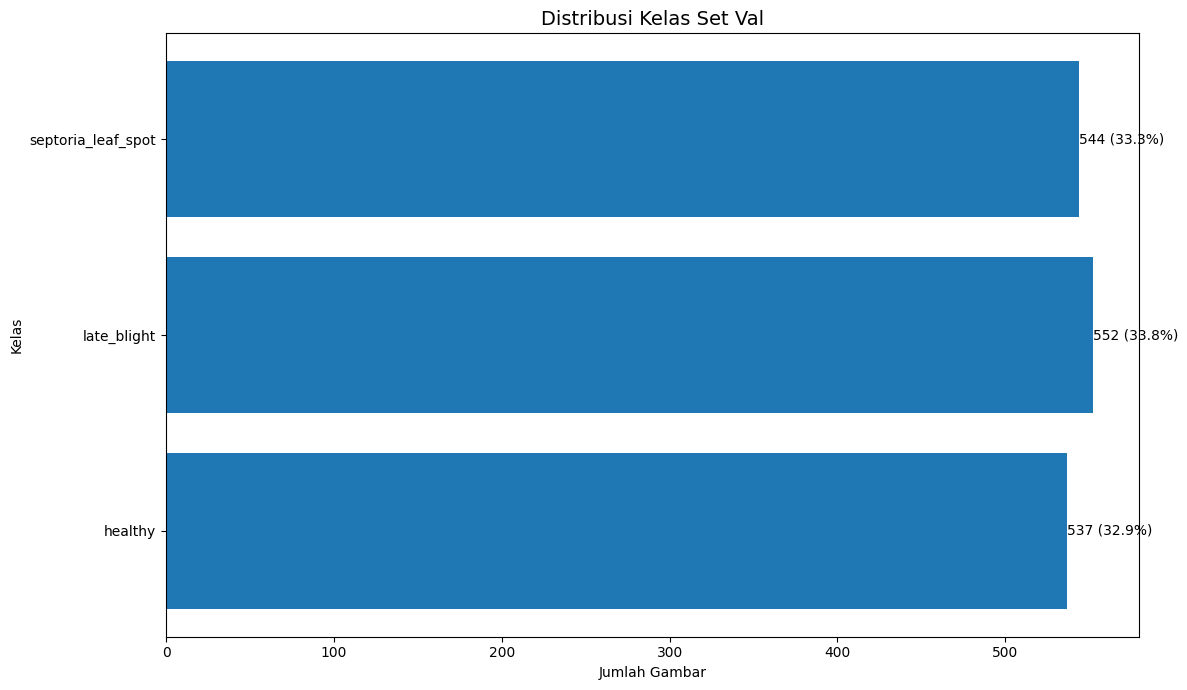

In [25]:
# Eksekusi fungsi plot_class_names_distribution untuk split val
plot_class_names_distribution(SRC_DIR, "val", EXTENSIONS, THRESHOLD)

Berdasarkan distribusi plot dari split val di atas, dapat dilihat bahwa;
1. Total data sebanyak 1633 data,
2. Maks sampel sebanyak 552 data,
3. Min sampel sebanyak 536, dan
4. Ratio imbalance senilai 1.03 dengan skala balance = 1.0

Dengan persebaran tiap kelas sebanyak;
- *septoria_leaf_spot* = 33.4% (545)
- *late_blight* = 33.8% (552)
- *healthy* = 32.8% (536)

Dengan data di atas dapat disimpulkan bahwa *dataset val* terbilang seimbang.


Ringkasan Distribusi Data (TEST SET)
Total Data : 1634
Maks Sampel: 552
Min Sampel : 537
Ratio Imbalance: 1.03



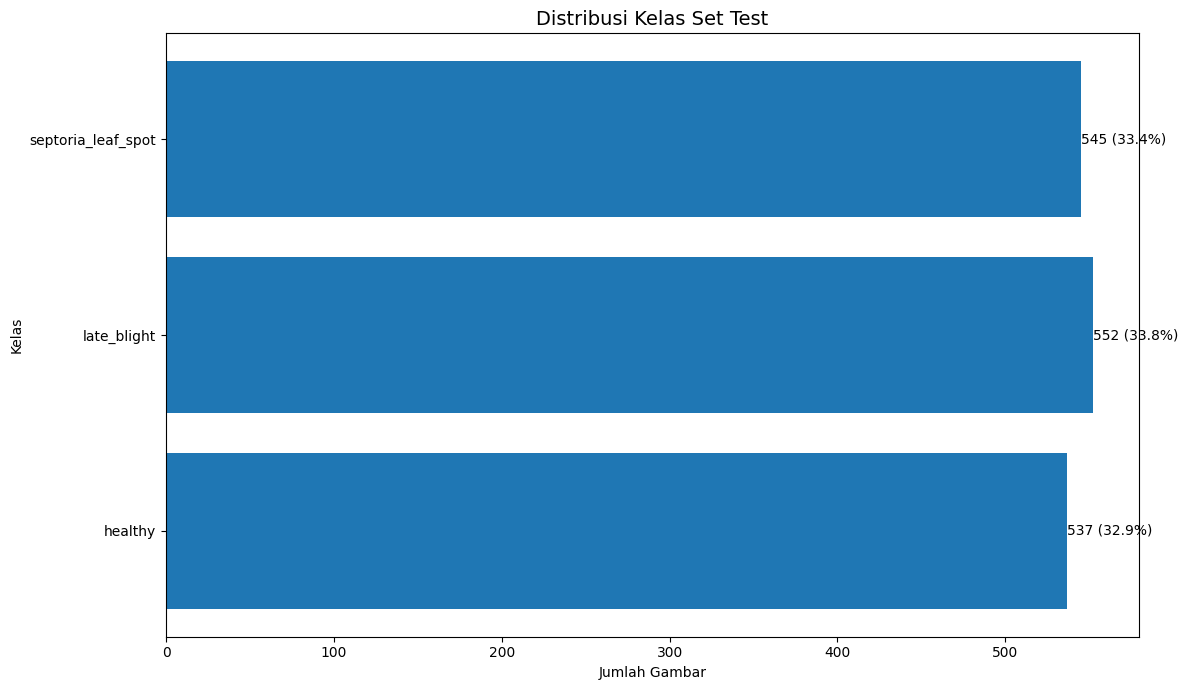

In [26]:
# Eksekusi fungsi plot_class_names_distribution untuk split test
plot_class_names_distribution(SRC_DIR, "test", EXTENSIONS, THRESHOLD)

Berdasarkan distribusi plot dari split test di atas, dapat dilihat bahwa;
1. Total data sebanyak 1633 data,
2. Maks sampel sebanyak 552 data,
3. Min sampel sebanyak 537, dan
4. Ratio imbalance senilai 1.03 dengan skala balance = 1.0

Dengan persebaran tiap kelas sebanyak;
- *septoria_leaf_spot* = 33.3% (544)
- *late_blight* = 33.8% (552)
- *healthy* = 32.9% (537)

Dengan data di atas dapat disimpulkan bahwa *dataset test* terbilang seimbang.


### Images Sample Visualization

Setelah berhasil melakukan *plot* distribusi kelas, selanjutnya  kita akan membuat fungsi untuk visualisasi gambar dataset. Fungsi ini akan menampilkan 5 sampel gambar berdasarkan *split* yang dipilih. Berikut adalah fungsi untuk visualisasi tersebut.

#### Config

In [27]:
# Config
SRC_DIR = '/content/dataset' # Path dataset sumber
EXTENSIONS = ('.jpg', '.jpeg') # Ekstensi gambar yang valid
SAMPLES = 5 # Jumlah sampel per kelas yang ingin divisualisasikan

#### Utility

In [28]:
def visualize_sample_images(src_dir, split, img_ext, samples_per_class):
  """
  Menampilkan sampel gambar dari setiap kelas

  Args:
    - src_dir: Direktori sumber dataset
    - split: Split dataset
    - img_ext: Ekstensi gambar yang valid
    - samples_per_class: Jumlah sampel per kelas yang ingin ditampilkan
  """

  split_path = os.path.join(src_dir, split) # Path dataset untuk split tertentu (train/val/test)
  class_names = sorted(os.listdir(split_path)) # Ambil daftar kelas

  # Iterasi tiap kelas dan filter hanya file dengan ekstensi gambar yang diizinkan
  for class_name in class_names:
    class_name_path = os.path.join(split_path, class_name)
    images = [
        img for img in os.listdir(class_name_path)
        if img.lower().endswith(img_ext)
    ]

    # Ambil sampel gambar secara acak
    sample_images = random.sample(
        images,
        min(samples_per_class, len(images))
    )

    # Membuat figure untuk menampilkan sampel
    plt.figure(figsize=(15, 3))

    # Iterasi setiap gambar sampel
    for i, img_name in enumerate(sample_images):
      img_path = os.path.join(class_name_path, img_name)
      img = Image.open(img_path) # Membuka gambar

      plt.subplot(1, len(sample_images), i+1) # Menentukan posisi subplot
      plt.imshow(img) # Menampilkan gambar
      plt.title(class_name)  # Judul kelas
      plt.axis('off')

    plt.suptitle(f"Sampel Gambar {class_name.capitalize()}")
    plt.tight_layout()
    plt.show()

#### Execution

Setelah berhasil mendefinisikan fungsi visualize_sample_images, eksekusi fungsi tersebut dengan menjalankan kode di bawah sesuai dengan split tertentu.

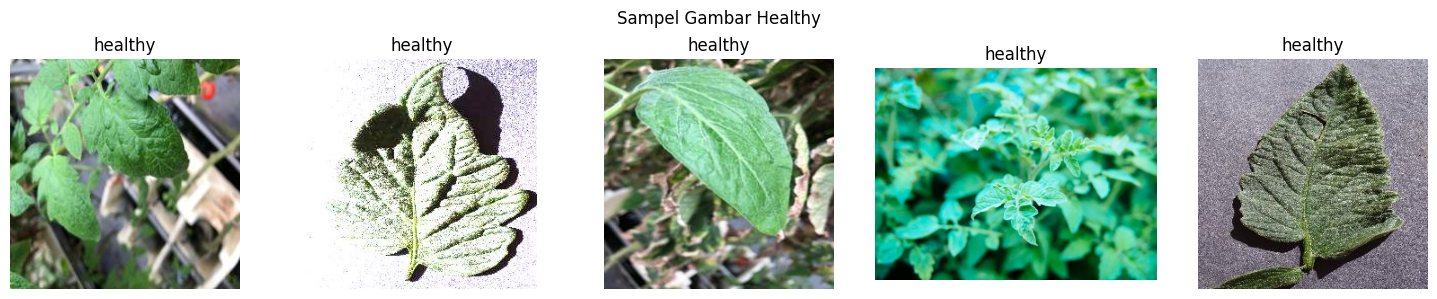

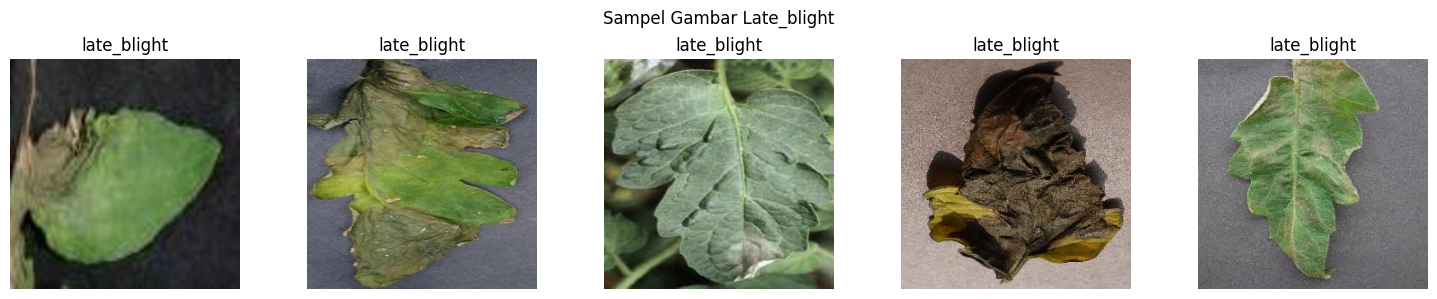

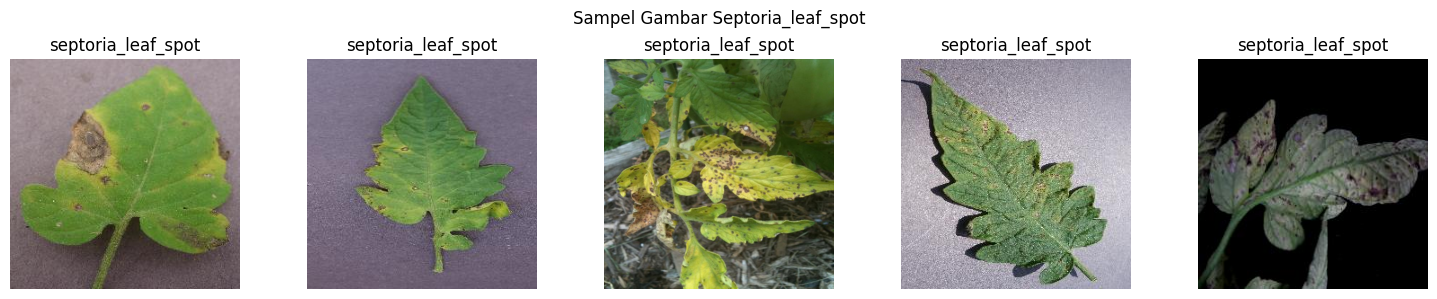

In [29]:
# Eksekusi fungsi visualize_sample_images untuk split train
visualize_sample_images(SRC_DIR, 'train', EXTENSIONS, SAMPLES)

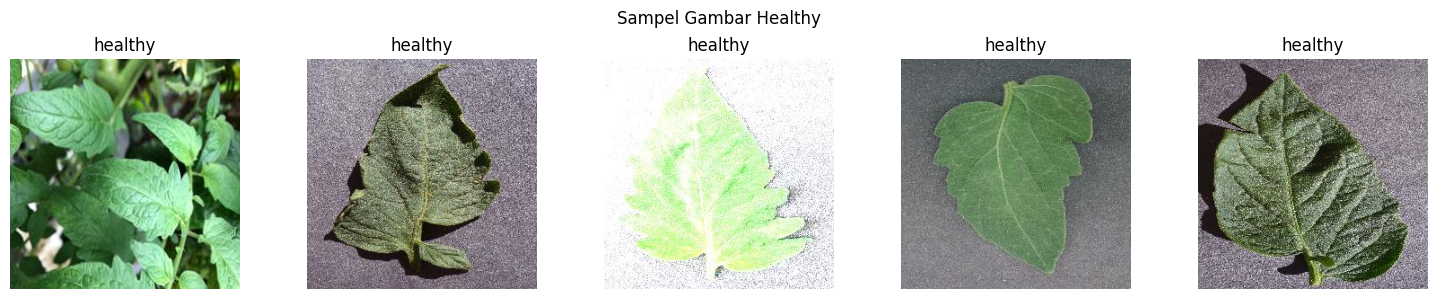

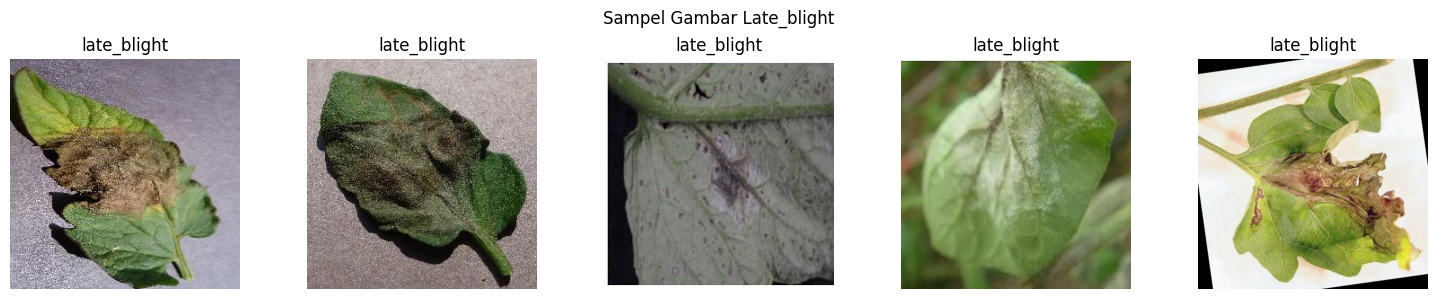

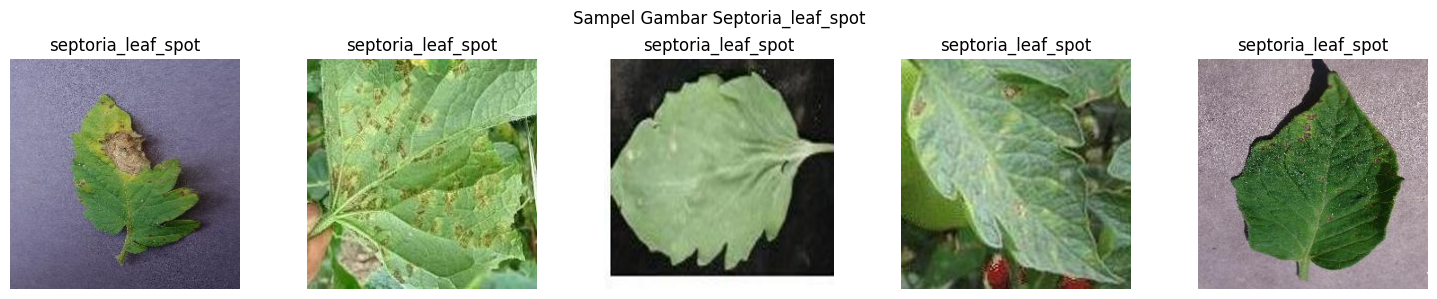

In [30]:
# Eksekusi fungsi visualize_sample_images untuk split val
visualize_sample_images(SRC_DIR, 'val', EXTENSIONS, SAMPLES)

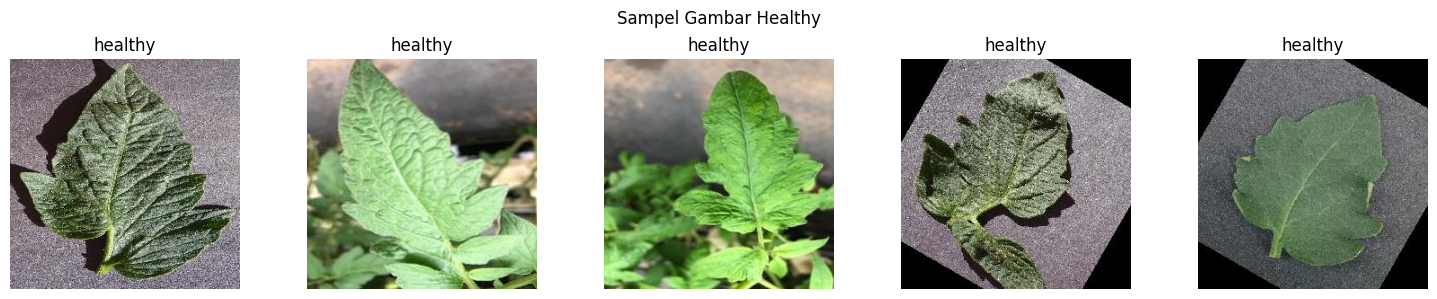

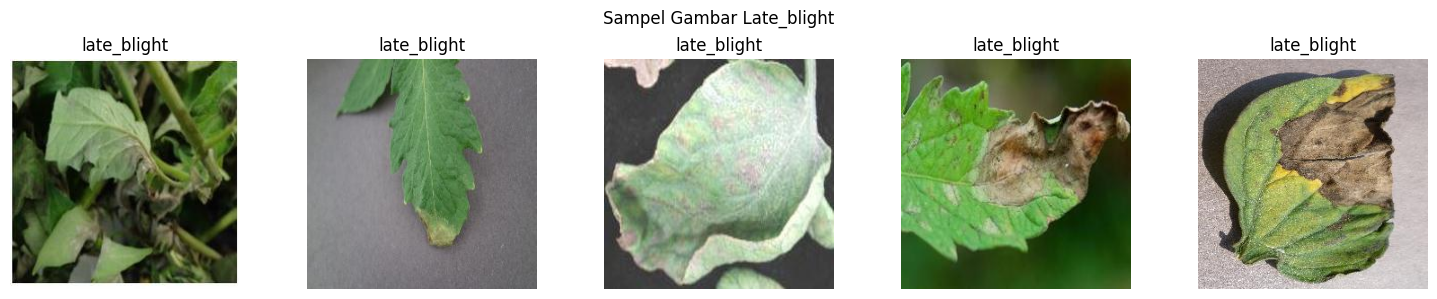

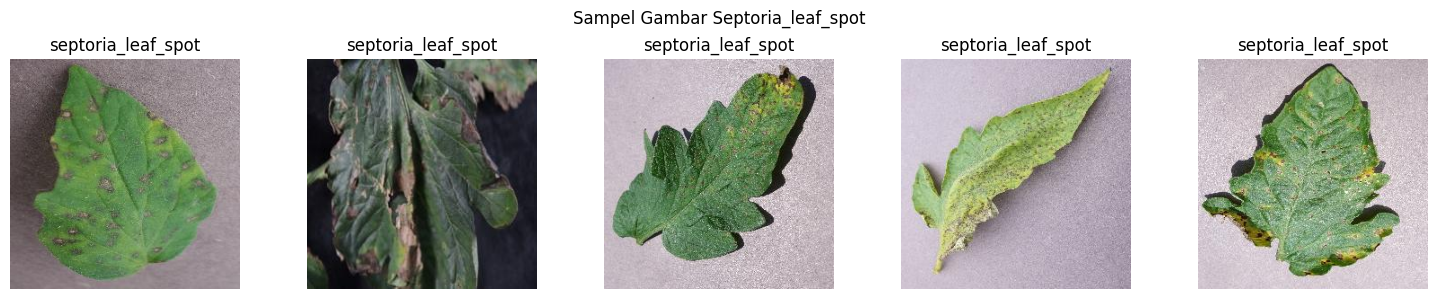

In [31]:
# Eksekusi fungsi visualize_sample_images untuk split test
visualize_sample_images(SRC_DIR, 'test', EXTENSIONS, SAMPLES)

## Dataset Preparation

Setelah berhasil melakukan *plot* distribusi kelas dan visualisasi gambar dataset, tahap selanjutnya adalah mempersiapkan dataset sebagai bahan *training* model. Dataset yang dipersiapkan ini nantinya akan di-*convert* ke dalam bentuk *tensorflow dataset*. Tahap-tahap persiapan ini terdiri dari beberapa fungsi *utility* yaitu,
1. *get_paths_and_labels*: Fungsi ini bertujuan untuk mengambil semua path dari gambar beserta label dari masing-masing gambar.2
2. *filter_valid_files*: Fungsi ini akan melakukan *filter* terhadap semua gambar. Jika gambar valid makan simpan, jika gambar tidak valid maka hapus.
3. *load_image*: Fungsi ini nantinya akan membantu dalam memuat gambar ketika pembuatan dataset sesuai dengan fungsi *build_dataset*.
3. *build_image*: Fungsi *build_image* adalah fungsi utama pada tahap ini yang bertujuan untuk membuat dataset ke dalam bentuk *tf.data.Dataset* agar model dapat melakukan *training* dengan dataset yang sudah dipersiapkan dengan baik.

### Config

In [32]:
# Config
TRAIN_DIR = "/content/dataset/train"  # Path dataset untuk training
VAL_DIR   = "/content/dataset/val"    # Path dataset untuk validation
TEST_DIR  = "/content/dataset/test"   # Path dataset untuk testing
EXTENSIONS = ('.jpg', '.jpeg') # Ekstensi gambar yang valid
BATCH_SIZE = 32        # Jumlah sampel dalam satu batch
IMG_SIZE = (224, 224)  # Ukuran gambar input model (height, width)

### Utilities

In [33]:
def get_paths_and_labels(src_dir, img_ext):
  """
  Mengambil semua path gambar dan labelnya

  Args:
    - src_dir: Direktori sumber dataset
    - img_ext: Ekstensi gambar yang valid

  Returns:
    - paths: Path gambar
    - labels: Label gambar
    - class_names: Nama kelas
  """

  # Ambil folder kelas
  class_names = sorted([
    class_name for class_name in os.listdir(src_dir)
    if os.path.isdir(os.path.join(src_dir, class_name))
  ])

  # Mapping kelas ke label numerik
  class_name_to_index = {name: i for i, name in enumerate(class_names)}

  paths = [] # List untuk menyimpan path gambar
  labels = [] # List untuk menyimpan label numerik gambar

  # Iterasi setiap kelas
  for class_name in class_names:
    class_name_dir = os.path.join(src_dir, class_name)

    # Iterasi setiap file dalam kelas lalu simpan path gambar dan label jika ekstensi gambar valid
    for file in os.listdir(class_name_dir):
      if file.lower().endswith(img_ext):
        paths.append(os.path.join(class_name_dir, file))
        labels.append(class_name_to_index[class_name])

  return paths, labels, class_names

In [34]:
def filter_valid_files(paths, labels):
  """
  Memfilter path gambar yang valid dan menghapus yang tidak valid

  Args:
    - paths: Path gambar
    - labels: Label gambar

  Returns:
    - valid_paths: Path gambar yang valid
    - valid_labels: Label gambar yang valid
  """

  valid_paths = []   # Menyimpan path gambar yang valid
  valid_labels = []  # Menyimpan label gambar yang valid

  # Iterasi setiap pasangan path dan label
  for path, label in zip(paths, labels):
    try:
      img_bytes = tf.io.read_file(path) # Membaca file gambar

      # Cek apakah file asli JPG/JPEG atau tidak
      if not tf.io.is_jpeg(img_bytes):
        raise ValueError("Gambar bukan file JPG/JPEG asli")

      img = tf.image.decode_jpeg(img_bytes, channels=3) # Validasi apakah gambar dapat didecode

      # Cek apakah dimensi sesuai (3D. H, W, C)
      if img.ndim != 3:
        raise ValueError("Gambar tidak valid. Dimensi tidak sesuai.")

      # Baca shape gambar apakah valid atau tidak
      if img.shape[-1] != 3 or img.shape[0] == 0 or img.shape[1] == 0:
        print(f"Shape gambar tidak sesuai {img.shape}: {path}")
        continue

      valid_paths.append(path)    # Simpan path jika gambar valid
      valid_labels.append(label)  # Simpan label gambar
    except:
      print(f"Gambar tidak valid: {path}")

  return valid_paths, valid_labels

In [35]:
def load_image(path, label, img_size):
  """
  Memuat gambar dari path dan melakukan preprocessing

  Args:
    - path: Path gambar
    - label: Label gambar

  Returns:
    - img: Gambar yang telah di-load dan di-preprocess
    - label: Label gambar
  """

  img_bytes = tf.io.read_file(path) # Membaca file gambar dari path
  img = tf.image.decode_jpeg(img_bytes, channels=3) # Decode gambar menjadi tensor RGB
  img = tf.image.resize(img, img_size) # Mengubah ukuran gambar menjadi 224x224
  img = tf.cast(img, tf.float32) / 255.0 # Normalisasi nilai pixel ke rentang 0-1
  img = tf.ensure_shape(img, [img_size[0], img_size[1], 3]) # Cek shape
  return img, label

In [36]:
def build_dataset(paths, labels, batch_size, img_size, shuffle=False):
  """"
  Membangun dataset dari path gambar dan label

  Args:
    - paths: Path gambar
    - labels: Label gambar
    - batch_size: Ukuran batch
    - shuffle: Apakah melakukan shuffle pada dataset

  Returns:
    - ds: Dataset yang telah di-build
  """

  # Membuat dataset dari path gambar dan label
  ds = tf.data.Dataset.from_tensor_slices((paths, labels))

  # Mengacak urutan dataset
  if shuffle:
    ds = ds.shuffle(len(paths), reshuffle_each_iteration=True)

   # Memuat dan memproses gambar menggunakan fungsi load_image
  ds = ds.map(
      lambda path, label: load_image(path, label, img_size),
      num_parallel_calls=tf.data.AUTOTUNE
  )
  ds = ds.batch(batch_size) # Mengelompokkan data menjadi batch
  ds = ds.prefetch(tf.data.AUTOTUNE) # Prefetch untuk meningkatkan performa pipeline data

  return ds

### Execution

Setelah berhasil mendefinisikan fungsi *utility* selanjutnya adalah eksekusi fungsi yang telah dibuat tersebut dengan kode di bawah.

Pertama-tama, kita akan mengambil path dari setiap gambar dan labelnya dengan fungsi *get_paths_and_labels* seperti kode di bawah.

In [37]:
# Eksekusi fungsi get_paths_and_labels untuk data training
train_paths, train_labels, class_names = get_paths_and_labels(TRAIN_DIR, EXTENSIONS)
# Eksekusi fungsi get_paths_and_labels untuk data validation
val_paths, val_labels, _ = get_paths_and_labels(VAL_DIR, EXTENSIONS)
# Eksekusi fungsi get_paths_and_labels untuk data testing
test_paths, test_labels, _ = get_paths_and_labels(TEST_DIR, EXTENSIONS)

# Menampilkan jumlah data pada setiap subset dataset
print(f"Jumlah Train : {len(train_paths)}")  # Total data training
print(f"Jumlah Val   : {len(val_paths)}")    # Total data validation
print(f"Jumlah Test  : {len(test_paths)}")   # Total data testing

# Menampilkan daftar nama kelas pada dataset
print(f"Class Names  : {class_names}")

Jumlah Train : 7620
Jumlah Val   : 1633
Jumlah Test  : 1634
Class Names  : ['healthy', 'late_blight', 'septoria_leaf_spot']


Setelah berhasil mengambil *path* dari gambar dan label serta menampilkan jumlah data tiap *split*nya, selanjutnya adalah melakukan validasi terhadap *file* gambar tersebut kemudian mulai membangun dataset dengan fungsi *build_dataset* dengan mengeksekusi blok kode di bawah.

In [38]:
# Eksekusi fungsi filter_valid_files pada dataset training
train_paths, train_labels = filter_valid_files(train_paths, train_labels)
# Eksekusi fungsi filter_valid_files pada dataset validation
val_paths, val_labels = filter_valid_files(val_paths, val_labels)
# Eksekusi fungsi filter_valid_files pada dataset testing
test_paths, test_labels = filter_valid_files(test_paths, test_labels)

# Eksekusi fungsi build_dataset untuk training
train_ds = build_dataset(train_paths, train_labels,
                         batch_size=BATCH_SIZE,
                         img_size=IMG_SIZE,
                         shuffle=True)

# Eksekusi fungsi build_dataset untuk validation
val_ds = build_dataset(val_paths, val_labels,
                       batch_size=BATCH_SIZE,
                       img_size=IMG_SIZE)

# Eksekusi fungsi build_dataset untuk testing
test_ds = build_dataset(test_paths, test_labels,
                        batch_size=BATCH_SIZE,
                        img_size=IMG_SIZE)

Gambar tidak valid: /content/dataset/train/healthy/edible-tomato-leaves.jpg
Gambar tidak valid: /content/dataset/train/healthy/2013-08-20-05.jpg


## Model Building

Setelah berhasil membuat dataset ke dalam bentuk *tensorflow dataset*, tibalah saatnya pada tahap membangun model. Model yang kita bangun adalah model *Convolutional Neural Network*. Model berbasis arsitektur *CNN* ini adalah model yang paling cocok dalam penanganan klasifikasi gambar. Mari kita mulai bangun modelnya dengan kode di bawah.

### Model Architecture

In [39]:
# Arsitektur model CNN
model = Sequential([
  # Input gambar berukuran 224x224 dengan 3 channel RGB
  Input(shape=(224, 224, 3)),

  # Blok Conv pertama
  Conv2D(16, (3, 3), padding='same', activation='relu'),
  MaxPooling2D(2, 2), # Downsampling untuk mengurangi dimensi fitur map

  # Blok Conv kedua
  Conv2D(32, (3, 3), padding='same', activation='relu'),
  MaxPooling2D(2, 2),

  # Blok Conv ketiga
  Conv2D(64, (3, 3), padding='same', activation='relu'),
  MaxPooling2D(2, 2),

  # Blok Conv keempat
  Conv2D(128, (3, 3), padding='same', activation='relu'),
  MaxPooling2D(2, 2),

  # Mengubah feature map 2D menjadi vektor 1D
  Flatten(),

  Dense(128, activation='relu'), # Fully connected layer
  Dense(3, activation='softmax') # Output layer untuk klasifikasi 3 kelas
])

### Model Training Config

In [40]:
# Konfigurasi proses training model
model.compile(
    optimizer=Adam(learning_rate=3e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

### Model Summary

In [41]:
# Menampilkan ringkasan dari arsitektur model
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,309,219 (12.62 MB)

 Trainable params: 3,309,219 (12.62 MB)

 Non-trainable params: 0 (0.00 B)

### Model Callbacks

Sebelum melatih model, alangkah baiknya kita menginisiasi *callback* yang akan kita gunakan terhadap *training* model. Callback itu sendiri adalah suatu fungsi yang akan dipanggil ketika proses *training* sedang berjalan. Hal ini berguna agar saat proses *training* berjalan dapat dipantau, dikontrol, ataupun dimodifikasi. Untuk *project* ini *callback* digunakan adalah sebagai berikut.
1. *EarlyStopAccuracy*: *Callback* ini digunakan untuk menghentikan proses *training* ketika *accuracy* model pada saat *training* telah mencapai angka tertentu.
2. *EarlyStopping*: Meskipun memiliki nama yang hampir sama dengan *callback* yang pertama, namun bedanya adalah *callback* ini akan menghentikan proses *training* ketika model tidak menunjukkan kemajuan *metric* yang dipantau pada saat proses *training* berjalan. Biasanya pada *callback* ini *metric* yang dipantau adalah *val_loss*.
3. *ReduceLROnPlateau*: Berbeda dengan dua *calback* yang sebelumnya, *callback* ini akan melakukan modifikasi terhadap *learning_rate* jika *metric* yang dipantau tidak mengindikasikan kemajuan. Biasanya pada *callback* ini *metric* yang dipantau adalah *val_loss* juga.

In [42]:
# Callback custom untuk menghentikan training jika accuracy mencapai threshold tertentu
class EarlyStopAtAccuracy(Callback):
  # Inisialisasi threshold accuracy
  def __init__(self, threshold=0.99):
    super().__init__()
    self.threshold = threshold

  # Method yang dijalankan setiap akhir epoch
  def on_epoch_end(self, epoch, logs=None):
    logs = logs or {}
    acc = logs.get("accuracy") # Mengambil nilai training accuracy

    # Jika accuracy mencapai threshold, hentikan training
    if acc is not None and acc >= self.threshold:
      print(f"\nAccuracy mencapai {self.threshold}, training dihentikan.")
      self.model.stop_training = True

# Callback untuk menghentikan training jika validation loss tidak membaik
early_stop = EarlyStopping(
    monitor='val_loss',          # Memantau validation loss
    patience=5,                  # Menunggu 5 epoch tanpa improvement
    restore_best_weights=True,   # Mengembalikan bobot terbaik setelah training berhenti
    verbose=1
)

# Callback untuk menurunkan learning rate jika model stagnan
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',  # Memantau validation loss
    factor=0.5,          # Mengurangi learning rate sebesar 50%
    patience=2,          # Menunggu 2 epoch tanpa improvement
    min_lr=1e-6,         # Batas minimum learning rate
    verbose=1
)

### Model Training

In [43]:
EPOCHS = 30 # Jumlah epoch training
early_stop_acc = EarlyStopAtAccuracy() # Membuat instance callback early stop berdasarkan accuracy

# Train model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stop, reduce_lr, early_stop_acc],
)

Epoch 1/30
239/239 ━━━━━━━━━━━━━━━━━━━━ 34s 93ms/step - accuracy: 0.6923 - loss: 0.7135 - val_accuracy: 0.8114 - val_loss: 0.4754 - learning_rate: 3.0000e-04
Epoch 2/30
239/239 ━━━━━━━━━━━━━━━━━━━━ 14s 57ms/step - accuracy: 0.8342 - loss: 0.4261 - val_accuracy: 0.8359 - val_loss: 0.4260 - learning_rate: 3.0000e-04
Epoch 3/30
239/239 ━━━━━━━━━━━━━━━━━━━━ 16s 66ms/step - accuracy: 0.8693 - loss: 0.3157 - val_accuracy: 0.8677 - val_loss: 0.3059 - learning_rate: 3.0000e-04
Epoch 4/30
239/239 ━━━━━━━━━━━━━━━━━━━━ 14s 58ms/step - accuracy: 0.8951 - loss: 0.2573 - val_accuracy: 0.8904 - val_loss: 0.2845 - learning_rate: 3.0000e-04
Epoch 5/30
239/239 ━━━━━━━━━━━━━━━━━━━━ 21s 60ms/step - accuracy: 0.9226 - loss: 0.1970 - val_accuracy: 0.8800 - val_loss: 0.3022 - learning_rate: 3.0000e-04
Epoch 6/30
239/239 ━━━━━━━━━━━━━━━━━━━━ 14s 59ms/step - accuracy: 0.9319 - loss: 0.1697 - val_accuracy: 0.8934 - val_loss: 0.2611 - learning_rate: 3.0000e-04
Epoch 7/30
239/239 ━━━━━━━━━━━━━━━━━━━━ 22s 65ms/ste

### Model Early Testing

Setelah berhasil melatih model seperti tahap yang ada di atas, selanjutnya adalah melakukan *early testing* terhadap model yang telah dikembangkan. Untuk tahap ini kita dapat melakukannya dengan cara *model.evaluate()* seperti kode di bawah ini.

In [44]:
# Testing performa model menggunakan dataset test
test_loss, test_acc = model.evaluate(test_ds) # Menghitung nilai loss dan accuracy pada data test

# Menampilkan hasil testing model
print("Test Loss :", test_loss)        # Nilai loss pada dataset test
print("Test Accuracy :", test_acc)     # Nilai akurasi model pada dataset test

52/52 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - accuracy: 0.9296 - loss: 0.1938
Test Loss : 0.19379737973213196
Test Accuracy : 0.9296205639839172


## Model Evaluation

Setelah model berhasil dikembangkan dan dilakukan *early testing*, selanjutnya masuklah ke tahap yang lebih dalam untuk melakukan evaluasi penuh terhadap kinerja model. Untuk melakukan evaluasi model lebih dalam pada *project* ini, kita akan mengevaluasinya dengan empat metode dari *sklearn*, yaitu *accuracy_score*, *confusion_matrix*, *classification_report*, dan *roc_curve*. Keempat metode ini memiliki penjelasan seperti berikut.
1. *accuracy_score*: *accuracy_score* ini adalah fungsi dari *sklearn* yang digunakan untuk menghitung tingkat akurasi suatu model klasifikasi. Fungsi ini membandingkan label sebenarnya dengan label hasil prediksi model.
2. *confusion_matrix*: *confusion_matrix* sendiri adalah fungsi dari *sklearn* yang digunakan untuk melihat secara detail hasil prediksi model klasifikasi, yaitu berapa banyak data yang:
    - Diprediksi benar
    - Diprediksi salah
    - Salahnya di kelas mana

    Berbeda dengan *accuracy* yang hanya memberi 1 angka, *confusion matrix* memberi tabel evaluasi yang lebih lengkap.

3. *classification_report*: Sedangkan *classification_report* adalah fungsi dari *sklearn* yang digunakan untuk menampilkan ringkasan lengkap performa model klasifikasi dalam bentuk tabel. Berbeda dengan:

    - accuracy_score → hanya 1 angka akurasi
    - confusion_matrix → tabel prediksi vs label asli

    *classification_report* memberikan beberapa metrik sekaligus untuk setiap kelas.

4. *roc_curve*: Kemudian *roc_curve* adalah fungsi dari *skleanr* yang digunakan untuk membuat *ROC Curve* (*Receiver Operating Characteristic Curve*), yaitu grafik untuk mengevaluasi kemampuan model klasifikasi dalam membedakan kelas. ROC curve biasanya digunakan pada model klasifikasi probabilistik, seperti *CNN* yang menghasilkan *probability* output dari *softmax/sigmoid*.

### Config

In [45]:
# Config
CLASS_NAMES = ['healthy', 'late_blight', 'septoria_leaf_spot']
CLASS_LEN = len(CLASS_NAMES)

### Utilities

In [46]:
def plot_history(history):
  """
  Menampilkan grafik evaluasi model

  Args:
    - history: Riwayat pelatihan model
  """

  acc = history.history['accuracy']
  val_acc = history.history['val_accuracy']
  loss = history.history['loss']
  val_loss = history.history['val_loss']

  epochs = range(len(acc))

  plt.plot(epochs, acc, 'r')
  plt.plot(epochs, val_acc, 'b')
  plt.title('Training and Validation Accuracy')
  plt.ylabel('accuracy')
  plt.xlabel('epoch')
  plt.legend(['train', 'val'], loc='upper left')
  plt.show()

  plt.plot(epochs, loss, 'r')
  plt.plot(epochs, val_loss, 'b')
  plt.ylabel('loss')
  plt.xlabel('epoch')
  plt.legend(['train', 'val'], loc='upper left')
  plt.title('Training and Validaion Loss')
  plt.show()

In [47]:
def collect_predictions(model, dataset):
  """
  Mengumpulkan prediksi dari model pada dataset

  Args:
    - model: Model yang akan diuji
    - dataset: Dataset yang akan digunakan untuk prediksi

  Returns:
    - y_true: Label sebenarnya
    - y_pred: Label yang diprediksi
    - y_score: Skor probabilitas
  """

  y_true = []   # Menyimpan label sebenarnya
  y_pred = []   # Menyimpan label hasil prediksi
  y_score = []  # Menyimpan probabilitas prediksi model

  # Iterasi setiap batch pada dataset
  for images, labels in dataset:
    preds = model.predict(images, verbose=0) # Melakukan prediksi pada batch gambar

    y_true.extend(labels.numpy())                 # Menambahkan label sebenarnya
    y_pred.extend(np.argmax(preds, axis=1))       # Mengambil kelas dengan probabilitas tertinggi
    y_score.extend(preds)                         # Menyimpan seluruh skor probabilitas

  print("Pengumpulan data prediksi selesai.")
  # Mengembalikan hasil dalam bentuk array
  return np.array(y_true), np.array(y_pred), np.array(y_score)

In [48]:
def evaluate_accuracy(y_true, y_pred):
  """
  Menghitung akurasi dari prediksi

  Args:
    - y_true: Label sebenarnya
    - y_pred: Label yang diprediksi
  """

  # Menghitung nilai akurasi menggunakan sklearn
  accuracy = accuracy_score(y_true, y_pred)

  correct = np.sum(y_true == y_pred)  # Menghitung jumlah prediksi yang benar
  total = len(y_true)                 # Menghitung total data
  wrong = total - correct             # Menghitung jumlah prediksi yang salah

  print("Accuracy Evaluation")
  print(f"Total data        : {total}")        # Menampilkan jumlah seluruh data
  print(f"Prediksi benar    : {correct}")      # Menampilkan jumlah prediksi benar
  print(f"Prediksi salah    : {wrong}")        # Menampilkan jumlah prediksi salah
  print(f"Accuracy score    : {accuracy:.4f} ({accuracy*100:.2f}%)")  # Menampilkan nilai akurasi

In [49]:
def evaluate_confusion_matrix(y_true, y_pred, class_names):
  """
  Menampilkan confusion matrix

  Args:
    - y_true: Label sebenarnya
    - y_pred: Label yang diprediksi
    - class_names: Nama kelas
  """

  # Menghitung confusion matrix dari label asli dan prediksi
  cm = confusion_matrix(y_true, y_pred)

  plt.figure(figsize=(6,5))  # Membuat figure untuk visualisasi
  sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')  # Menampilkan confusion matrix dalam bentuk heatmap

  plt.xticks(np.arange(len(class_names))+0.5, class_names, rotation=45)  # Mengatur label kelas pada sumbu X
  plt.yticks(np.arange(len(class_names))+0.5, class_names)               # Mengatur label kelas pada sumbu Y

  print("Confussion Matrix\n")

  plt.xlabel('Predicted')  # Label sumbu X (kelas hasil prediksi)
  plt.ylabel('True')       # Label sumbu Y (kelas sebenarnya)
  plt.title('Confusion Matrix')

  plt.tight_layout()  # Mengatur layout agar tidak terpotong
  plt.show()

In [50]:
def evaluate_classification_report(y_true, y_pred, class_names):
  """
  Menampilkan classification report

  Args:
    - y_true: Label sebenarnya
    - y_pred: Label yang diprediksi
    - class_names: Nama kelas
  """

  print("Classification Report\n")
  print(classification_report(
      y_true,
      y_pred,
      target_names=class_names,  # Menentukan nama kelas pada laporan
      digits=3                   # Mengatur jumlah angka desimal yang ditampilkan
  ))

In [51]:
def plot_multiclass_roc(y_true, y_score, class_len, class_names):
  """
  Menampilkan ROC Curve untuk multi-class classification

  Args:
    - y_true: Label sebenarnya
    - y_score: Skor probabilitas
    - class_len: Jumlah kelas
    - class_names: Nama kelas
  """

  # Mengubah label menjadi format biner (one-vs-rest)
  y_true_bin = label_binarize(y_true, classes=np.arange(class_len))

  plt.figure(figsize=(7,6))

  fpr = dict()     # Menyimpan False Positive Rate tiap kelas
  tpr = dict()      # Menyimpan True Positive Rate tiap kelas
  roc_auc = dict()  # Menyimpan nilai AUC tiap kelas

  # Iterasi untuk setiap kelas
  for i in range(class_len):
    fpr[i], tpr[i], _ = roc_curve(
        y_true_bin[:, i],  # Label sebenarnya dalam format biner
        y_score[:, i]      # Probabilitas prediksi untuk kelas ke-i
    )

    # Menghitung nilai AUC untuk kelas tersebut
    roc_auc[i] = auc(fpr[i], tpr[i])

    plt.plot(
        fpr[i],
        tpr[i],
        label=f"{class_names[i]} (AUC={roc_auc[i]:.3f})" # Menampilkan kurva ROC dan nilai AUC
    )

  # Garis diagonal sebagai baseline classifier acak
  plt.plot([0,1],[0,1],'--')

  print("ROC Curve\n")

  plt.xlabel('False Positive Rate')  # Label sumbu X
  plt.ylabel('True Positive Rate')   # Label sumbu Y
  plt.title('ROC Curve Multi-Class')

  plt.legend()
  plt.grid()
  plt.show()

  # Menampilkan rata-rata AUC seluruh kelas
  print(f"\nMacro Averange AUC: {np.mean(list(roc_auc.values()))}")

### Execution

#### Prediction Collecting

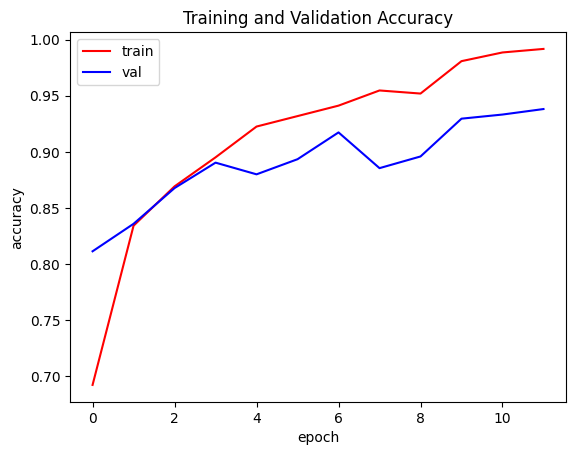

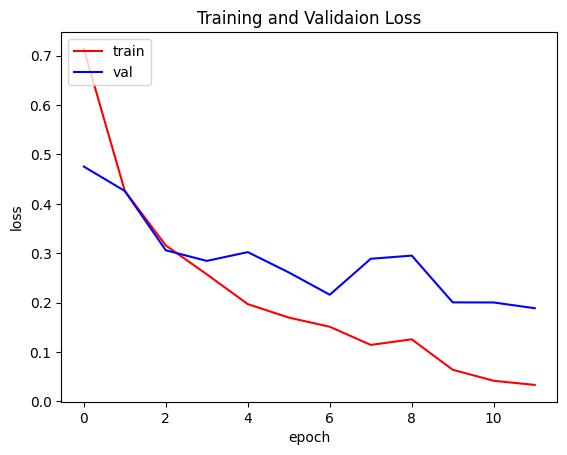

In [52]:
# Eksekusi fungsi plot_history
plot_history(history)

In [53]:
# Eksekusi fungsi collect_predictions untuk mengumpulkan data prediksi
y_true, y_pred, y_score = collect_predictions(model, test_ds)

Pengumpulan data prediksi selesai.


#### Accuracy Score

In [54]:
# Eksekusi fungsi evaluate_accuracy
evaluate_accuracy(y_true, y_pred)

Accuracy Evaluation
Total data        : 1634
Prediksi benar    : 1519
Prediksi salah    : 115
Accuracy score    : 0.9296 (92.96%)


#### Confusion Matrix

Confussion Matrix



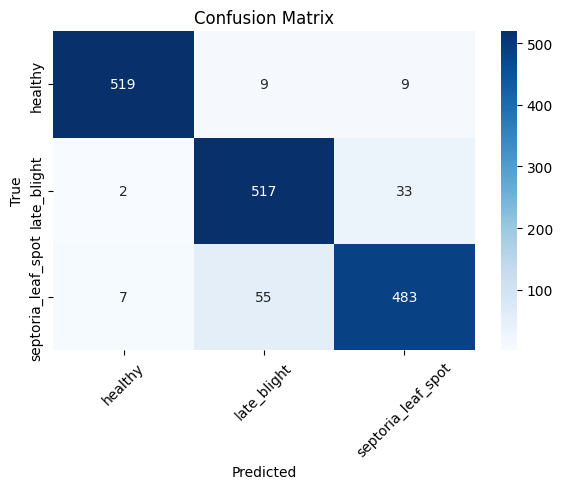

In [55]:
# Eksekusi fungsi evaluate_confusion_matrix
evaluate_confusion_matrix(
    y_true,
    y_pred,
    class_names
)

#### Classification Report

In [56]:
# Eksekusi fungsi evaluate_classification_report
evaluate_classification_report(
    y_true,
    y_pred,
    class_names
)

Classification Report

                    precision    recall  f1-score   support

           healthy      0.983     0.966     0.975       537
       late_blight      0.890     0.937     0.913       552
septoria_leaf_spot      0.920     0.886     0.903       545

          accuracy                          0.930      1634
         macro avg      0.931     0.930     0.930      1634
      weighted avg      0.931     0.930     0.930      1634



#### ROC Curve

ROC Curve



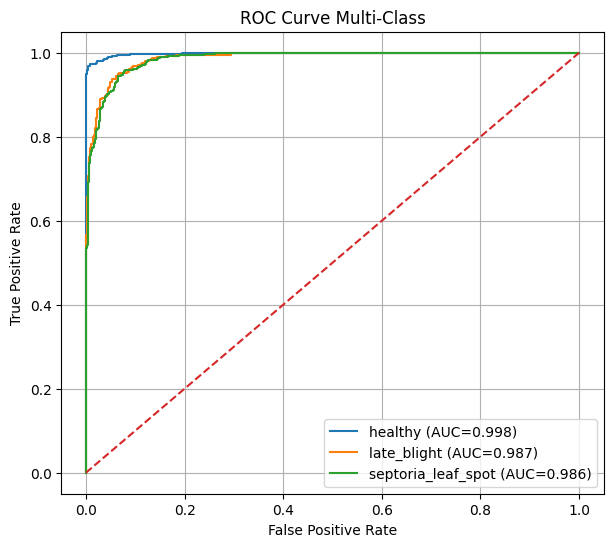


Macro Averange AUC: 0.9903152827744379


In [57]:
# Eksekusi fungsi plot_multiclass_roc
plot_multiclass_roc(
    y_true,
    y_score,
    CLASS_LEN,
    CLASS_NAMES
)

## Saving Model

Kemudian, pada tahap terakhir adalah melakukan *save* terhadap model yang sudah dikembangkan dan dipastikan performa nya berjalan baik. Pada *project* ini, model akan disimpan ke dalam *tensorflow lite*.


Mari kita lakukan simpan model ke dalam tiga *format* yang sudah disebutkan di atas dengan kode di bawah.

### Saved Model

In [58]:
# Menentukan lokasi penyimpanan model yang telah dilatih
MODEL_EXPORT_PATH = "model.keras"

# Menyimpan model ke format Keras native (.keras)
model.save(MODEL_EXPORT_PATH)

In [59]:
# Download model ke mesin lokal
files.download('model.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Tensorflow Lite

In [60]:
# Membuat converter TensorFlow Lite dari model SavedModel
converter = tf.lite.TFLiteConverter.from_keras_model(model)

# Mengaktifkan optimisasi default untuk memperkecil ukuran model dan meningkatkan performa
converter.optimizations = [tf.lite.Optimize.DEFAULT]

# Menentukan operasi TensorFlow yang didukung oleh model TFLite
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS,
    tf.lite.OpsSet.SELECT_TF_OPS
]

# Menentukan tipe data yang didukung oleh model
converter.target_spec.supported_types = [tf.float32]

# Melakukan konversi model ke format TensorFlow Lite
tflite_model = converter.convert()

# Menyimpan model hasil konversi ke file .tflite
with open("tomato_disease_model.tflite", "wb") as f:
    f.write(tflite_model)

Saved artifact at '/tmp/tmphggda32p'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  138990580471888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138990580472848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138990580472656: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138990580473232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138990580472272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138990580474000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138990580472080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138990580472464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138990580473424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138990580474384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13899058047304

In [61]:
# Download model ke mesin lokal
files.download('tomato_disease_model.tflite')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Predict Using Tensorflow Lite

Setelah berhasil menyimpan model ke dalam tiga *format* yang sudah dibahas. Selanjutnya untuk memastikan model dapat bekerja dengan baik, mari kita lakukan uji coba terhadap model yang telah dilatih dengan model yang telah disimpan. Pada tahap ini kita akan melakukan uji cobanya dengan model *tensorflow lite*.

#### Config

In [62]:
# Membuat interpreter TensorFlow Lite menggunakan model .tflite
interpreter = tf.lite.Interpreter(
    model_path='tomato_disease_model.tflite'
)

# Mengalokasikan tensor yang dibutuhkan oleh model
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()   # Mengambil informasi tensor input model
output_details = interpreter.get_output_details() # Mengambil informasi tensor output model

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


#### Utilities

In [63]:
def tflite_predict(image):
  """
  Melakukan prediksi menggunakan model TensorFlow Lite

  Args:
    - image: Gambar yang akan diprediksi

  Returns:
    - output: Hasil prediksi dari model
  """

  # Jika input berupa TensorFlow tensor, ubah menjadi numpy array
  if hasattr(image, 'numpy'):
    image = image.numpy()

  # Mengubah tipe data input menjadi float32 sesuai kebutuhan model
  image = image.astype(np.float32)

# Memasukkan data gambar ke tensor input model
  interpreter.set_tensor(
    input_details[0]['index'],
    image
  )

  # Menjalankan inference menggunakan model TFLite
  interpreter.invoke()

  # Mengambil hasil prediksi dari tensor output
  output = interpreter.get_tensor(
    output_details[0]['index']
  )

  return output

In [64]:
def get_random_sample(dataset):
  """
  Mengambil sampel gambar secara acak dari dataset

  Args:
    - dataset: Dataset yang akan diambil sampel
  """
  images_list = []  # Menyimpan seluruh gambar dari dataset
  labels_list = []  # Menyimpan seluruh label dari dataset

  # Iterasi setiap batch pada dataset
  for images, labels in dataset:
    images_list.extend(images.numpy())  # Mengubah tensor gambar menjadi numpy dan menambahkannya ke list
    labels_list.extend(labels.numpy())  # Mengubah tensor label menjadi numpy dan menambahkannya ke list

  # Memilih indeks gambar secara acak
  idx = np.random.randint(len(images_list))

  return (
    np.expand_dims(images_list[idx], axis=0),  # Mengambil gambar acak dan menambahkan dimensi batch
    labels_list[idx]                           # Mengembalikan label sebenarnya dari gambar tersebut
  )

#### Execution

In [65]:
# Eksekusi fungsi get_random_sample untuk mengambil sampel data
sample_image, sample_label = get_random_sample(test_ds)

print("True label:", class_names[sample_label])

True label: late_blight


In [66]:
original_pred = model.predict(sample_image) # Melakukan prediksi menggunakan model TensorFlow asli
tflite_pred = tflite_predict(sample_image)  # Melakukan prediksi menggunakan model TensorFlow Lite

# Menampilkan perbandingan probabilitas prediksi untuk setiap kelas
for i, name in enumerate(class_names):
    print(f"{name}")
    print(f"Original : {original_pred[0][i]*100:.2f}%")  # Probabilitas prediksi dari model asli
    print(f"TFLite   : {tflite_pred[0][i]*100:.2f}%")    # Probabilitas prediksi dari model TFLite
    print()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 478ms/step
healthy
Original : 0.00%
TFLite   : 0.00%

late_blight
Original : 99.81%
TFLite   : 99.81%

septoria_leaf_spot
Original : 0.19%
TFLite   : 0.19%



Berdasarkan prediksi di atas, dapat dilihat bahwa model asli memprediksi 99.81% adalah *late_blight* dan model *tflite* memprediksi 99.81% dan berdasarkan sampel yang diambil dari fungsi *get_random_sample* pada kode di atas dapat disimpulkan bahwa model bekerja dengan baik dalam memprediksi penyakit tomat melalui daun tumbuhannya.